In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten, InputLayer
import cv2
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

In [ ]:
DATA_PATH = '../data'
TRAIN_CSV_PATH = os.path.join(DATA_PATH, 'train.csv')
TEST_CSV_PATH = os.path.join(DATA_PATH, 'sample_submission.csv')
TRAIN_IMAGES_PATH = os.path.join(DATA_PATH, 'images', 'train')
TEST_IMAGES_PATH = os.path.join(DATA_PATH, 'images', 'test')
OUTPUT_PATH = 'output'

In [ ]:
os.makedirs(OUTPUT_PATH, exist_ok=True)

In [ ]:

train_data = pd.read_csv(TRAIN_CSV_PATH)
test_data = pd.read_csv(TEST_CSV_PATH)

In [ ]:

print(train_data['Target'][7])

train_data['Target1'] = train_data['Target'].apply(lambda x: x.strip(' '))
print(train_data['Target1'][7])

train_data['Target'] = train_data['Target'].apply(lambda x: x.strip(' '))
print(train_data['Target'][7])

13 20 
13 20
13 20


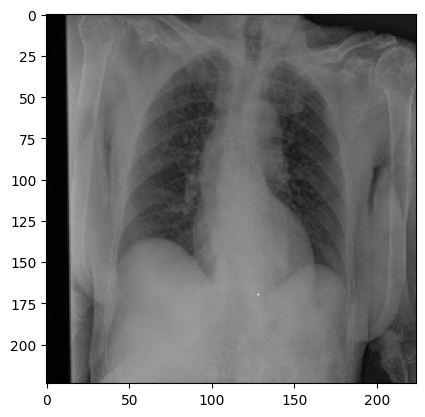

In [ ]:
sample_uid = train_data.loc[7].SOPInstanceUID
sample_img_path = os.path.join(TRAIN_IMAGES_PATH, f"{sample_uid}.png")
img = plt.imread(sample_img_path)
plt.imshow(img, cmap='gray')
plt.show()

In [ ]:

multi = []
multi_target = []
for i, val in enumerate(train_data.Target):
    if len(val) > 2:
        multi.append(train_data.iloc[i].SOPInstanceUID)
        multi_target.append(train_data.iloc[i].Target)


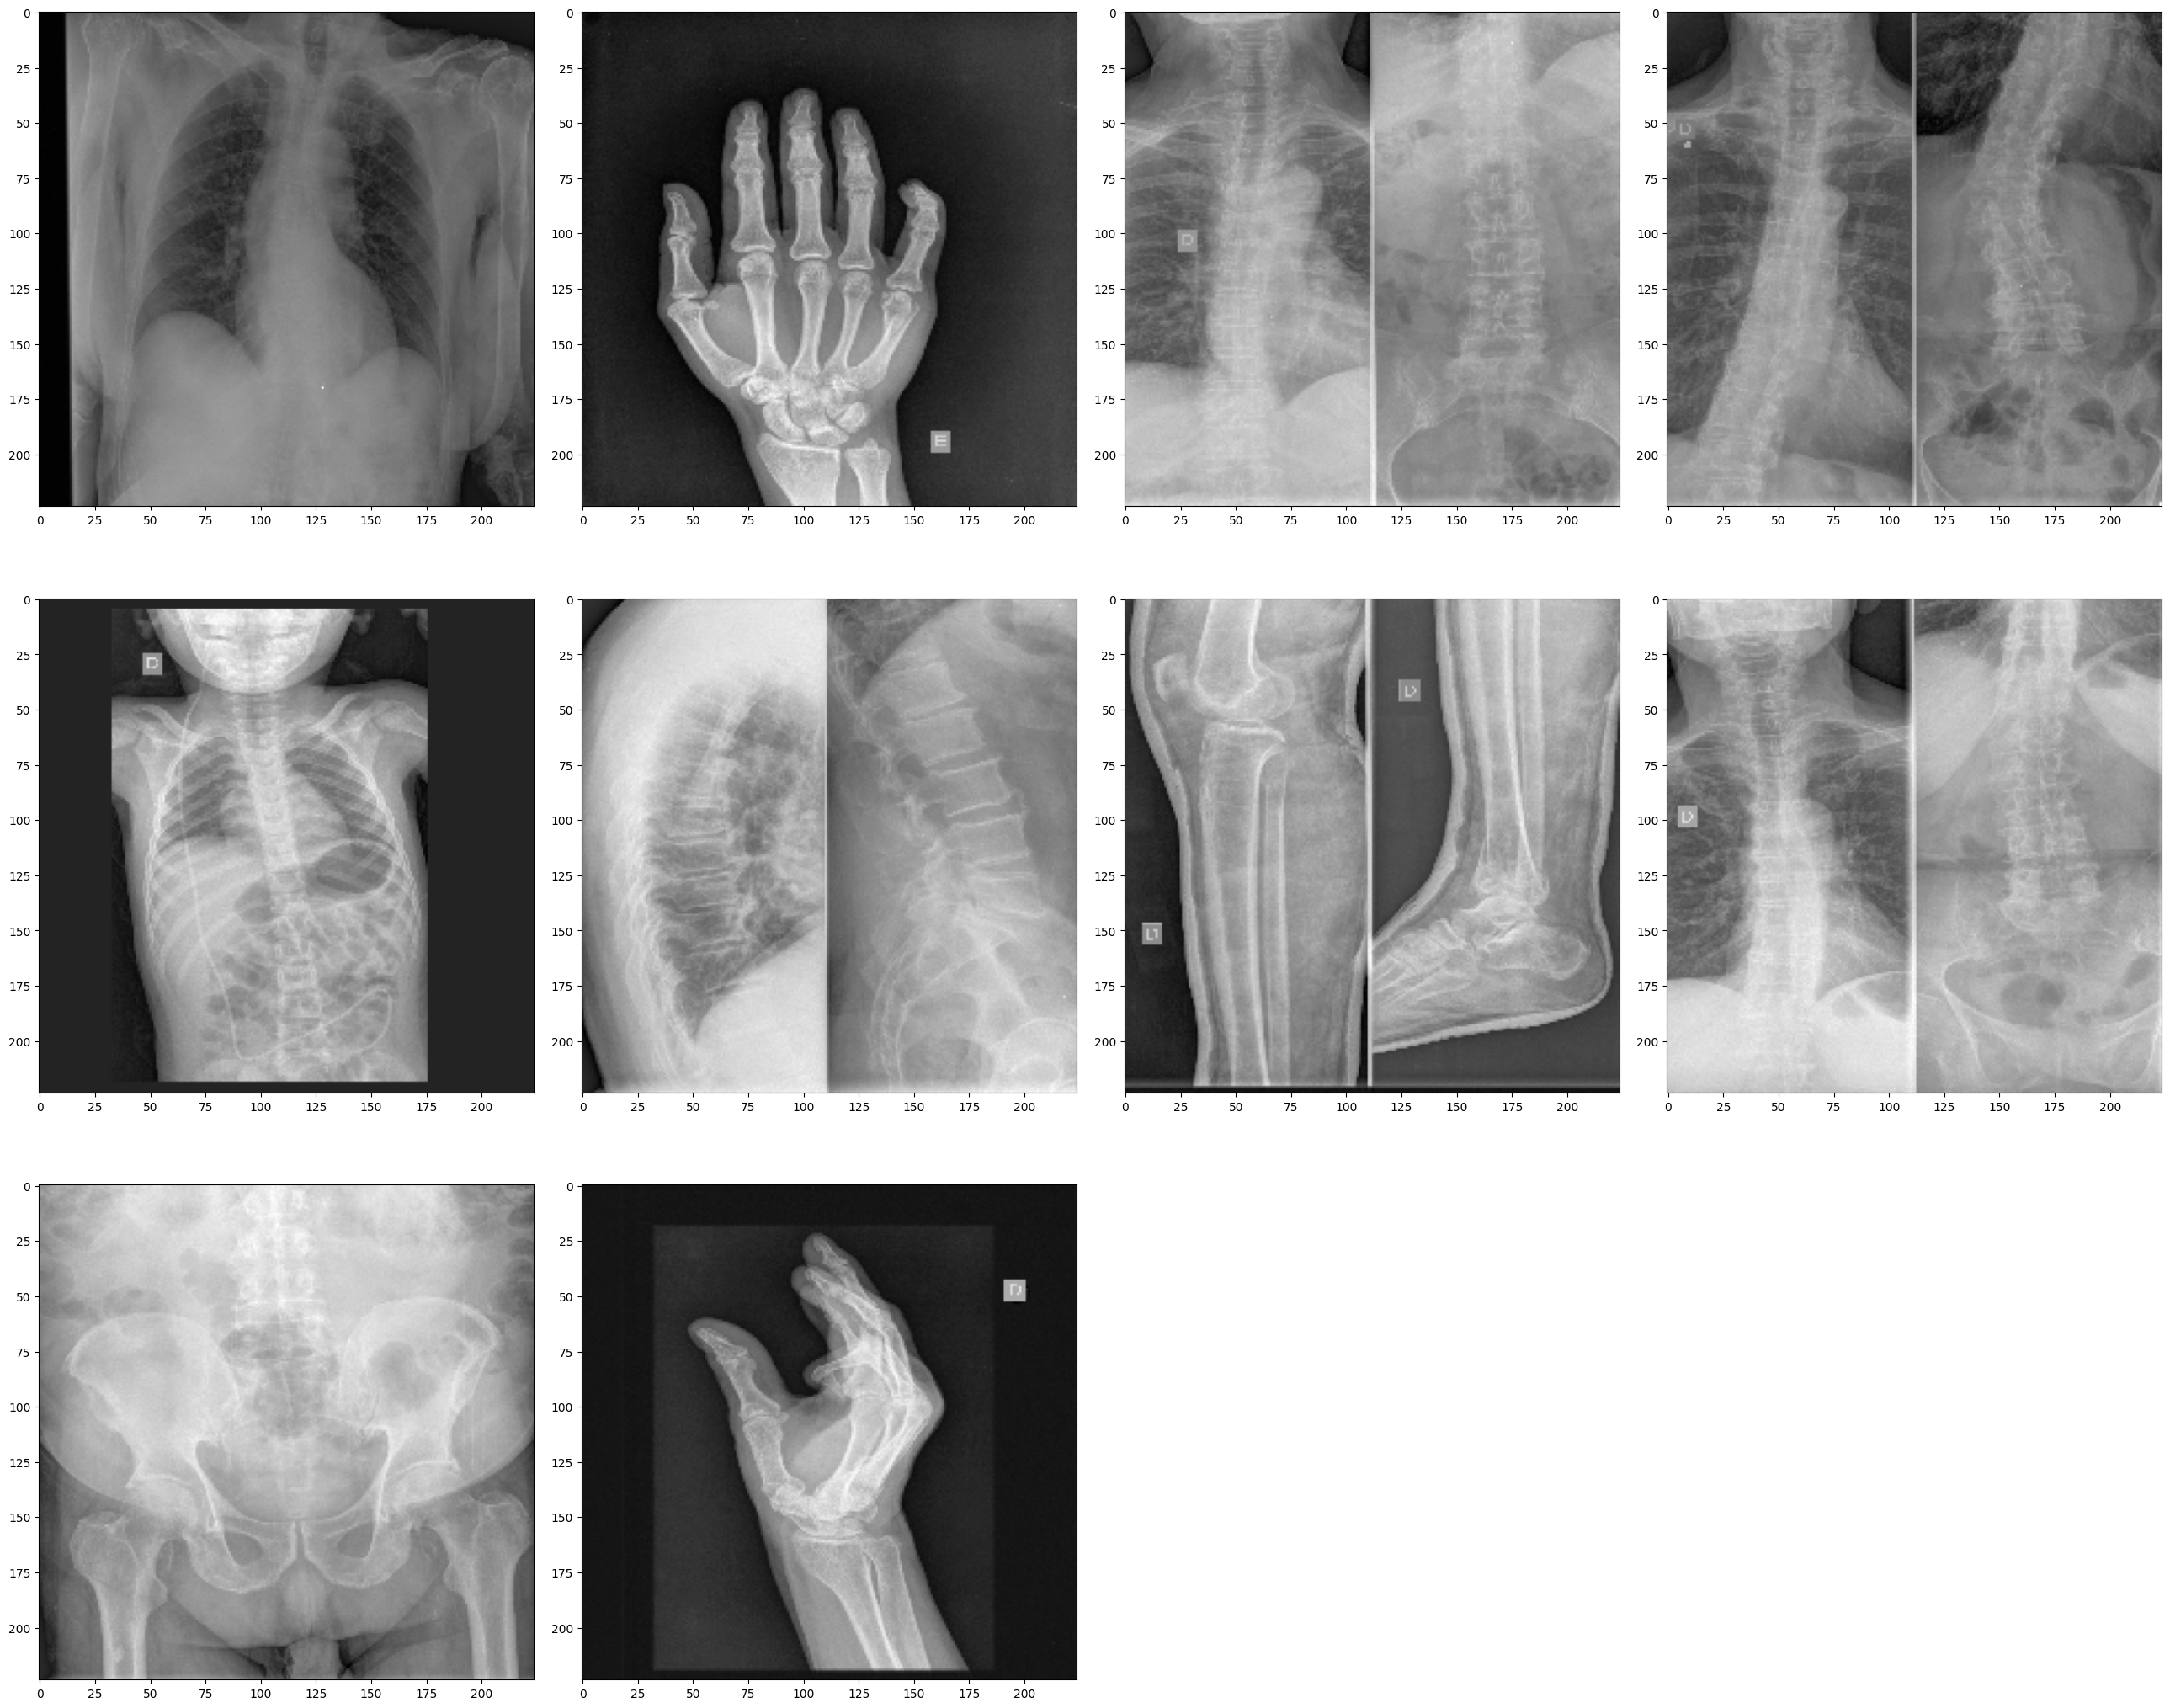

In [ ]:

plt.figure(figsize=(26, 28))
for i in range(min(10, len(multi))):
    plt.subplot(4, 4, i+1)
    img_path = os.path.join(TRAIN_IMAGES_PATH, f"{multi[i]}.png")
    img = plt.imread(img_path)
    plt.imshow(img, cmap='gray')
plt.tight_layout(pad=1.5)
plt.show()


In [ ]:

train_dff = pd.DataFrame()
train_dff['SOPInstanceUID'] = train_data['SOPInstanceUID'].copy()
train_dff['Target'] = train_data['Target'].copy()
print(train_dff.head(2))


                                      SOPInstanceUID Target
0  1.2.826.0.1.3680043.8.498.10025629581362719970...      0
1  1.2.826.0.1.3680043.8.498.10036150326276641158...     15


In [ ]:

def Names(label):
    if label == '0':
        return 'Abdomen'
    elif label == '1':
        return 'Ankle'
    elif label == '2':
        return 'Cervical Spine'
    elif label == '3':
        return 'Chest'
    elif label == '4':
        return 'Clavicles'
    elif label == '5':
        return 'Elbow'
    elif label == '6':
        return 'Feet'
    elif label == '7':
        return 'Finger'
    elif label == '8':
        return 'Forearm'
    elif label == '9':
        return 'Hand'
    elif label == '10':
        return 'Hip'
    elif label == '11':
        return 'Knee'
    elif label == '12':
        return 'Lower Leg'
    elif label == '13':
        return 'Lumbar Spine'
    elif label == '14':
        return 'Others'
    elif label == '15':
        return 'Pelvis'
    elif label == '16':
        return 'Shoulder'
    elif label == '17':
        return 'Sinus'
    elif label == '18':
        return 'Skull'
    elif label == '19':
        return 'Thigh'
    elif label == '20':
        return 'Thoracic Spine'
    elif label == '21':
        return 'Wrist'


In [ ]:

x, x1 = train_dff.iloc[7]['Target'].split(' ', 1)
x_name = Names(x)
x1_name = Names(x1)
print(x_name + ' ' + x1_name)

Lumbar Spine Thoracic Spine


In [ ]:

for i, val in enumerate(train_dff.Target):
    if len(val) > 2 and len(val) <= 6:
        x, x1 = train_dff.iloc[i]['Target'].split(' ', 1)
        x_name = Names(x)
        x1_name = Names(x1)
        total = x_name + ' ' + x1_name
        train_dff.at[i, 'label'] = total
    elif len(val) >= 7:
        x, x1, x2 = train_dff.iloc[i]['Target'].split(' ', 2)
        x_name = Names(x)
        x1_name = Names(x1)
        x2_name = Names(x2)
        total = x_name + ' ' + x1_name + ' ' + x2_name
        train_dff.at[i, 'label'] = total
    else:
        x = train_dff.iloc[i]['Target']
        x_name = Names(x)
        train_dff.at[i, 'label'] = x_name


In [ ]:
train_dff = pd.get_dummies(train_dff['label'])
train_dff['SOPInstanceUID'] = train_data['SOPInstanceUID']
train_dff['Target'] = train_data['Target']
print(train_dff.head(3))

   Abdomen  Abdomen Chest  Abdomen Pelvis  Ankle  Ankle Feet  \
0     True          False           False  False       False   
1    False          False           False  False       False   
2    False          False           False  False       False   

   Ankle Knee Lower Leg  Ankle Lower Leg  Cervical Spine  \
0                 False            False           False   
1                 False            False           False   
2                 False            False           False   

   Cervical Spine Lumbar Spine Thoracic Spine  Cervical Spine Thoracic Spine  \
0                                       False                          False   
1                                       False                          False   
2                                       False                          False   

   ...  Pelvis  Pelvis Thigh  Shoulder  Sinus  Skull  Thigh  Thoracic Spine  \
0  ...   False         False     False  False  False  False           False   
1  ...    True         

In [ ]:
new_train_data = pd.merge(train_data, train_dff, on='SOPInstanceUID')
print(new_train_data.head(5))
new_train_data.drop('Target_y', axis=1, inplace=True)
print(new_train_data.columns[3:])

                                      SOPInstanceUID Target_x Target1  \
0  1.2.826.0.1.3680043.8.498.10025629581362719970...        0       0   
1  1.2.826.0.1.3680043.8.498.10036150326276641158...       15      15   
2  1.2.826.0.1.3680043.8.498.10038426859954986240...       12      12   
3  1.2.826.0.1.3680043.8.498.10050991192143676483...       14      14   
4  1.2.826.0.1.3680043.8.498.10053309524595490852...        3       3   

   Abdomen  Abdomen Chest  Abdomen Pelvis  Ankle  Ankle Feet  \
0     True          False           False  False       False   
1    False          False           False  False       False   
2    False          False           False  False       False   
3    False          False           False  False       False   
4    False          False           False  False       False   

   Ankle Knee Lower Leg  Ankle Lower Leg  ...  Others  Pelvis  Pelvis Thigh  \
0                 False            False  ...   False   False         False   
1                 

In [ ]:
X = []
y = []

In [ ]:

for val in tqdm(new_train_data.SOPInstanceUID):
    idd = val
    img_path = os.path.join(TRAIN_IMAGES_PATH, f"{val}.png")

    try:
        img = plt.imread(img_path)
        img = cv2.resize(img, dsize=(128, 128))
        img_norm = cv2.normalize(img, None, alpha=0, beta=500, norm_type=cv2.NORM_MINMAX)
        y.append(np.ndarray.flatten(np.array(new_train_data.loc[new_train_data['SOPInstanceUID'] == idd][new_train_data.columns[3:]])))
        X.append(np.expand_dims(img, axis=-1))
    except Exception as e:
        print(f"Error loading image {img_path}: {e}")

X = np.array(X)
y = np.array(y)
print(f"Loaded {len(X)} images with {y.shape[1]} label features")


Loading and processing images...


 99%|█████████▉| 1725/1738 [18:54<00:08,  1.57it/s]

In [ ]:

fig = plt.figure(figsize=(26, 28))
for i in range(min(10, len(X))):
    plt.subplot(4, 4, i+1)
    plt.imshow(X[i].squeeze(), cmap='gray')
plt.tight_layout(pad=1.4)
plt.show()

if len(X) > 40:
    print(X[40].shape)
    plt.imshow(X[40].squeeze(), cmap='gray')
    plt.show()


In [ ]:

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
print(f"Training size: {x_train.shape}, Test size: {x_test.shape}")

In [ ]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1)
])


x_train_augmented = np.copy(x_train)
for i in tqdm(range(len(x_train))):
    if np.random.random() > 0.5:
        img_tensor = tf.convert_to_tensor(x_train[i])
        augmented = data_augmentation(img_tensor)
        x_train_augmented[i] = augmented.numpy()


In [ ]:

plt.figure(figsize=(15, 6))
for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i+6)
    plt.imshow(x_train_augmented[i].squeeze(), cmap='gray')
    plt.title("Augmented")
    plt.axis('off')
plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.optimizers import Adam



model = tf.keras.models.Sequential()

model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal', padding='same', input_shape=(128, 128, 1)))
model.add(tf.keras.layers.BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(tf.keras.layers.BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(256, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(tf.keras.layers.BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(512, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(tf.keras.layers.BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Dropout(0.5))
model.add(Flatten())
model.add(Dense(2048, activation="relu"))
model.add(tf.keras.layers.BatchNormalization())
model.add(Dropout(0.3))
model.add(Dense(1024, activation="relu"))
model.add(tf.keras.layers.BatchNormalization())
model.add(Dropout(0.3))
model.add(Dense(y.shape[1], activation="sigmoid"))

optimizer = Adam(learning_rate=0.001)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

In [ ]:


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1)
])


In [ ]:


callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=30),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_PATH, "best_model.h5"),
        monitor='val_loss',
        save_best_only=True
    )
]


In [ ]:
class_weights = {}
for i in range(y_train.shape[1]):
    pos_samples = np.sum(y_train[:, i])
    total = len(y_train)
    weight = total / (2 * pos_samples) if pos_samples > 0 else 1.0
    class_weights[i] = weight


In [ ]:
#training 1
history = model.fit(
    x_train, y_train,
    batch_size=4,
    callbacks=callbacks,
    epochs=100,
    validation_data=(x_test, y_test),
    class_weight=class_weights
)

In [ ]:
# Train model 2

history = model.fit(
    x_train, y_train,
    batch_size=8,
    callbacks=callbacks,
    epochs=50,
    validation_data=(x_test, y_test)
)


In [ ]:
#train model 3
history = model.fit(
    x_train, y_train,
    batch_size=16,
    callbacks=callbacks,
    epochs=25,
    validation_data=(x_test, y_test)
)

In [ ]:

model.evaluate(x_test, y_test)

In [ ]:
#model.save(f"{OUTPUT_PATH}/xray_classifier.keras")
model.save("xray_classifier.keras")

Testing

In [ ]:
#best_model = tf.keras.models.load_model(f"{OUTPUT_PATH}/best_model.h5")
best_model = tf.keras.models.load_model(os.path.join(OUTPUT_PATH, "best_model.h5"))

test_images = []
test_uids = []


In [ ]:
for uid in tqdm(test_data['SOPInstanceUID']):
    img_path = os.path.join(TEST_IMAGES_PATH, f"{uid}.png")

    try:
        img = plt.imread(img_path)
        img = cv2.resize(img, dsize=(128, 128))
        img_norm = cv2.normalize(img, None, alpha=0, beta=500, norm_type=cv2.NORM_MINMAX)
        test_images.append(np.expand_dims(img_norm, axis=-1))
        test_uids.append(uid)
    except Exception as e:
        print(f"Error {img_path}: {e}")

test_images = np.array(test_images)
print(f"Loaded {len(test_images)}  images")

predictions = best_model.predict(test_images)

In [ ]:

threshold = 0.5
binary_predictions = (predictions > threshold).astype(int)

submission = []
for i, uid in enumerate(test_uids):
    pred_indices = np.where(binary_predictions[i] == 1)[0]

    pred_columns = [new_train_data.columns[idx+3] for idx in pred_indices]
    numeric_labels = []
    for col in pred_columns:
        for label, name in Names.__dict__.items():
            if name == col:
                numeric_labels.append(label)

    if len(pred_indices) == 0:
        most_likely = np.argmax(predictions[i])
        pred_indices = [most_likely]
        pred_column = new_train_data.columns[most_likely+3]
        for label, name in Names.__dict__.items():
            if name == pred_column:
                numeric_labels.append(label)

    submission.append({
        'SOPInstanceUID': uid,
        'Target': ' '.join(numeric_labels)
    })

submission_df = pd.DataFrame(submission)
submission_df.to_csv(os.path.join(OUTPUT_PATH, "submission.csv"), index=False)



In [ ]:

random_indices = np.random.choice(len(test_images), min(5, len(test_images)), replace=False)

plt.figure(figsize=(20, 10))
for i, idx in enumerate(random_indices):
    plt.subplot(1, 5, i+1)
    plt.imshow(test_images[idx].squeeze(), cmap='gray')
    pred_classes = [new_train_data.columns[class_idx+3] for class_idx in np.where(binary_predictions[idx] == 1)[0]]
    plt.title('\n'.join(pred_classes))
    plt.axis('off')
plt.tight_layout()
plt.show()